# 03 Regression: what drives Delhi's AQI, and how strongly?

**Syllabus units:** Linear regression (5 marks) and Multiple linear regression (10 marks).
**Tutorial items:** 3 (confidence intervals for coefficients) and 4 (linear, polynomial and multiple regression).
**Outputs:** `outputs/tables/regression_comparison.csv`, `models/regression_model.json` (used by the app).

**Honest framing.** AQI is *computed* from the pollutant readings (the worst sub-index sets it), so regressing AQI
on pollutants partly recovers that formula by construction. These models therefore answer *which pollutant drives
AQI and how strongly*, not a new scientific discovery. The genuinely predictive work is the forecasting in notebook 05.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from src.utils import *
set_plot_style()

df = load_clean()
df["Season"] = pd.Categorical(df["Season"], SEASONS)
print("cleaned dataset:", df.shape)

cleaned dataset: (1826, 19)


## Design: one split for every model
All three models use the same random 80/20 split (seed 42) so their test scores are directly comparable. Because
daily data are autocorrelated, a random split is optimistic (neighbouring days leak information), so Part D also
reports a stricter **time-based test**: train on 2015-2018, test on 2019.

In [2]:
season_d = pd.get_dummies(df["Season"]).drop(columns="Winter").astype(float)   # Winter = baseline
X_all = pd.concat([df[POLLUTANTS], season_d], axis=1)
y_all = df["AQI"]
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=TEST_SIZE, random_state=SEED)
print(f"train {len(X_tr)} days | test {len(X_te)} days")

train 1460 days | test 366 days


## Part A: Simple linear regression, AQI on PM2.5
Model: AQI = β0 + β1·PM2.5 + ε.

Pearson r = 0.884


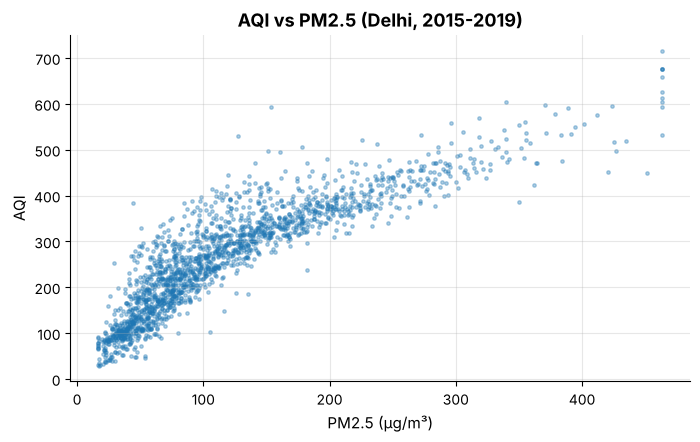

In [3]:
fig, ax = plt.subplots()
ax.scatter(df["PM2.5"], df["AQI"], s=6, alpha=.35)
ax.set(title="AQI vs PM2.5 (Delhi, 2015-2019)", xlabel="PM2.5 (µg/m³)", ylabel="AQI")
save_figure(fig, "03_scatter_pm25"); plt.show()
print(f"Pearson r = {df[['PM2.5', 'AQI']].corr().iloc[0, 1]:.3f}")

In [4]:
model = sm.OLS(y_tr, sm.add_constant(X_tr[["PM2.5"]])).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AQI   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     5269.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:38:45   Log-Likelihood:                -7942.1
No. Observations:                1460   AIC:                         1.589e+04
Df Residuals:                    1458   BIC:                         1.590e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        109.3204      2.595     42.132      0.0

In [5]:
b0, b1 = model.params
ci = model.conf_int().loc["PM2.5"]
print(f"Fitted line:   AQI = {b0:.2f} + {b1:.3f} x PM2.5")
print(f"R-squared:     {model.rsquared:.3f}   (adjusted {model.rsquared_adj:.3f})")
print(f"t-test slope:  t = {model.tvalues['PM2.5']:.1f}, p = {model.pvalues['PM2.5']:.2e}")
print(f"F-test:        F = {model.fvalue:.1f}, p = {model.f_pvalue:.2e}  (F = t^2 = {model.tvalues['PM2.5']**2:.1f})")
print(f"Slope 95% CI:  {ci[0]:.3f} to {ci[1]:.3f}")

Fitted line:   AQI = 109.32 + 1.303 x PM2.5
R-squared:     0.783   (adjusted 0.783)
t-test slope:  t = 72.6, p = 0.00e+00
F-test:        F = 5268.8, p = 0.00e+00  (F = t^2 = 5268.8)
Slope 95% CI:  1.267 to 1.338


Residual skewness 0.39, excess kurtosis 0.50, Jarque-Bera p = 4.9e-12
Breusch-Pagan p = 0.471
Durbin-Watson (residuals in date order) = 0.69


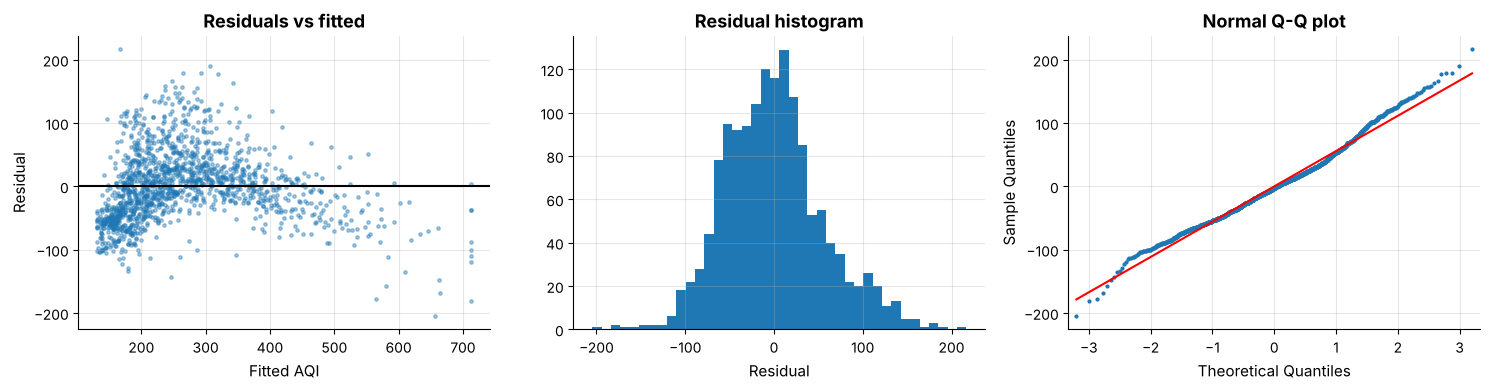

In [6]:
resid = model.resid
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(model.fittedvalues, resid, s=6, alpha=.4); ax[0].axhline(0, color="k")
ax[0].set(title="Residuals vs fitted", xlabel="Fitted AQI", ylabel="Residual")
ax[1].hist(resid, bins=40); ax[1].set(title="Residual histogram", xlabel="Residual")
sm.qqplot(resid, line="s", ax=ax[2], markersize=2); ax[2].set_title("Normal Q-Q plot")
plt.tight_layout(); save_figure(fig, "03_simple_residuals"); plt.show()

bp_s = het_breuschpagan(resid, model.model.exog)
jb = stats.jarque_bera(resid)
dw_time = durbin_watson(resid.sort_index())
print(f"Residual skewness {stats.skew(resid):.2f}, excess kurtosis {stats.kurtosis(resid):.2f}, Jarque-Bera p = {jb[1]:.2g}")
print(f"Breusch-Pagan p = {bp_s[1]:.3f}")
print(f"Durbin-Watson (residuals in date order) = {dw_time:.2f}")

At PM2.5 = 100: {'mean': 239.6, 'mean_se': 1.5, 'mean_ci_lower': 236.6, 'mean_ci_upper': 242.5, 'obs_ci_lower': 130.1, 'obs_ci_upper': 349.1}


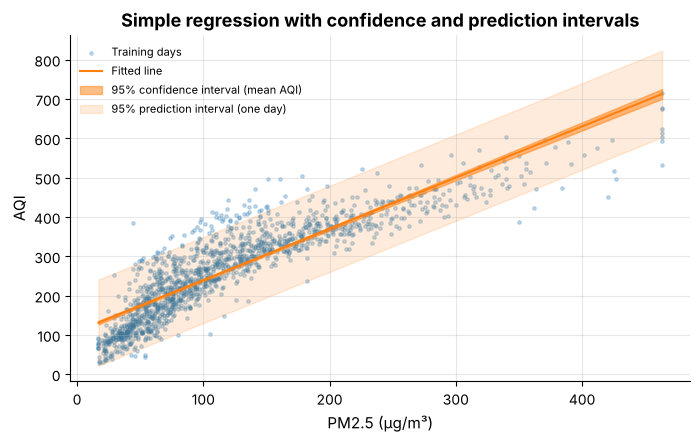

In [7]:
grid = pd.DataFrame({"PM2.5": np.linspace(X_tr["PM2.5"].min(), X_tr["PM2.5"].max(), 200)})
fr = model.get_prediction(sm.add_constant(grid)).summary_frame(alpha=1 - CONF_LEVEL)
fig, ax = plt.subplots()
ax.scatter(X_tr["PM2.5"], y_tr, s=6, alpha=.25, label="Training days")
ax.plot(grid["PM2.5"], fr["mean"], color="C1", label="Fitted line")
ax.fill_between(grid["PM2.5"], fr["mean_ci_lower"], fr["mean_ci_upper"], alpha=.5, color="C1",
                label="95% confidence interval (mean AQI)")
ax.fill_between(grid["PM2.5"], fr["obs_ci_lower"], fr["obs_ci_upper"], alpha=.15, color="C1",
                label="95% prediction interval (one day)")
ax.set(title="Simple regression with confidence and prediction intervals", xlabel="PM2.5 (µg/m³)", ylabel="AQI")
ax.legend(fontsize=8)
save_figure(fig, "03_simple_intervals"); plt.show()
at100 = model.get_prediction(np.array([[1.0, 100.0]])).summary_frame(alpha=.05)
print("At PM2.5 = 100:", at100.round(1).to_dict("records")[0])

In [8]:
pred = model.predict(sm.add_constant(X_te[["PM2.5"]]))
results = [{"Model": "Simple linear (PM2.5)", "k": 1, **regression_metrics(y_te, pred, n_features=1),
            "AIC": model.aic}]
pd.DataFrame(results).round(3)

,Model,k,R2,Adj_R2,RMSE,MAE,AIC
0,Simple linear (PM2.5),1,0.775,0.774,56.741,42.298,15888.151


**Simple linear regression: AQI on PM2.5** (80/20 split, seed 42)

* **Fitted line:** AQI = 109.3 + 1.303 × PM2.5. Each extra 1 µg/m³ of PM2.5 raises AQI by about 1.30 points on
  average. The intercept (109) is the AQI the other pollutants produce when PM2.5 is near zero; it is an
  extrapolation, since the lowest observed PM2.5 is about 17.
* **Coefficient of determination:** R² = 0.783, so PM2.5 alone explains 78% of the day-to-day variation in AQI.
* **Significance:** t = 72.6 for the slope and F = 5,269 = t² (p < 0.001 for both); with one predictor the t and
  F tests are the same test. The 95% confidence interval for the slope is 1.267 to 1.338.
* **Residual analysis:** residuals are centred on zero with mild right skew (0.39) and slightly heavy tails
  (excess kurtosis 0.50); Jarque-Bera rejects exact normality, but with 1,460 points the t-tests are robust to
  this. Breusch-Pagan p = 0.47, so constant variance is acceptable here. The Durbin-Watson statistic on residuals in
  date order is **0.69**, far below 2: errors on neighbouring days are strongly positively correlated, so the
  reported standard errors are too small. This is the first sign that time matters (notebook 05).
* **Intervals at PM2.5 = 100 µg/m³:** predicted mean AQI 239.6 with a 95% confidence interval of 236.6 to 242.5
  (where the *average* day lies), but a 95% prediction interval of 130 to 349 for a *single* day. The prediction
  interval is about 37 times wider because it includes the day's own random error.
* **Test set:** R² = 0.775, RMSE = 56.7 AQI points. The scatter bends at high PM2.5, motivating Part C.

## Part B: Multiple linear regression
All nine pollutants plus season as a categorical variable (three dummies, Winter = baseline).

In [9]:
model_m = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
print(model_m.summary())

                            OLS Regression Results                            
Dep. Variable:                    AQI   R-squared:                       0.881
Model:                            OLS   Adj. R-squared:                  0.880
Method:                 Least Squares   F-statistic:                     891.7
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:38:46   Log-Likelihood:                -7505.1
No. Observations:                1460   AIC:                         1.504e+04
Df Residuals:                    1447   BIC:                         1.510e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           80.0260      5.603     14.282   

### Standardised (beta) coefficients: which pollutant matters most?
Raw coefficients are in different units (CO in mg/m³, the rest in µg/m³), so they cannot be compared directly. A
beta coefficient is the change in AQI, in standard deviations, for a one-standard-deviation change in the pollutant.

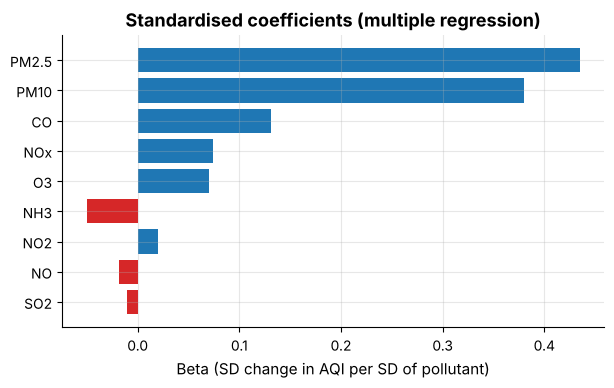

,coef (per unit),beta (standardised),p-value
PM2.5,0.6400,0.4348,0.0000
PM10,0.3786,0.3795,0.0000
CO,6.2400,0.1313,0.0000
NOx,0.2334,0.0741,0.0000
O3,0.3201,0.0698,0.0000
NH3,-0.3386,-0.0504,0.0001
NO2,0.1083,0.0204,0.2767
NO,-0.0668,-0.0188,0.2606
SO2,-0.1628,-0.0109,0.4601


In [10]:
beta = (model_m.params[POLLUTANTS] * X_tr[POLLUTANTS].std() / y_tr.std()).sort_values(key=abs, ascending=False)
coef_tab = pd.DataFrame({"coef (per unit)": model_m.params[POLLUTANTS], "beta (standardised)": beta,
                         "p-value": model_m.pvalues[POLLUTANTS]}).loc[beta.index]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(beta.index[::-1], beta.values[::-1], color=["C3" if v < 0 else "C0" for v in beta.values[::-1]])
ax.set(title="Standardised coefficients (multiple regression)", xlabel="Beta (SD change in AQI per SD of pollutant)")
save_figure(fig, "03_beta_coefficients"); plt.show()
coef_tab.round(4)

### Diagnostics: multicollinearity, heteroscedasticity, autocorrelation, influence

In [11]:
Xc = sm.add_constant(X_tr)
vif = pd.DataFrame({"Variable": Xc.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
vif = vif[vif["Variable"] != "const"].sort_values("VIF", ascending=False)
save_table(vif.round(3), "vif")
vif.round(2)

,Variable,VIF
1,PM2.5,5.81
2,PM10,4.91
4,NO2,4.25
3,NO,3.38
11,Monsoon,2.98
8,SO2,2.66
10,Summer,2.44
5,NOx,2.10
6,NH3,1.91
9,O3,1.66


Breusch-Pagan LM = 98.7, p = 9.97e-16
Durbin-Watson (date order) = 1.10
Cook's distance > 4/n: 110 of 1460 days; max = 0.050 (rule of thumb for concern: > 1)
|studentised residual| > 3: 11 days


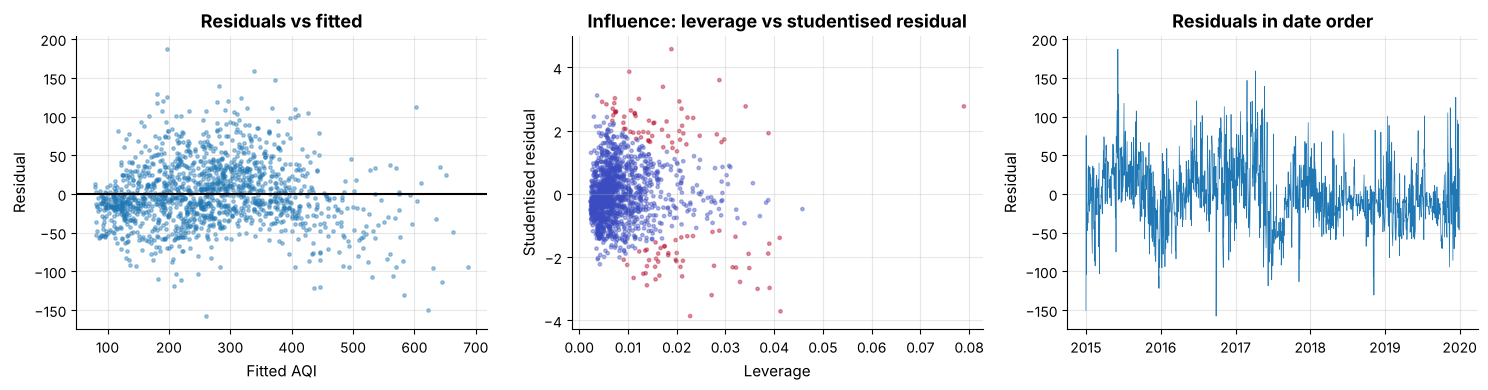

,Cooks,Date,AQI,PM2.5,PM10,CO
786,0.050337,2017-02-25,516.0,425.22,103.74,0.36
0,0.045209,2015-01-01,472.0,313.22,607.98,13.78
156,0.030660,2015-06-06,384.0,44.54,119.29,11.94
787,0.029274,2017-02-26,520.0,328.23,198.09,0.41
355,0.027456,2015-12-22,326.0,204.72,391.90,11.45


In [12]:
bp = het_breuschpagan(model_m.resid, model_m.model.exog)
dw = durbin_watson(model_m.resid.sort_index())
infl = model_m.get_influence()
cooks = infl.cooks_distance[0]
lev = infl.hat_matrix_diag
stud = infl.resid_studentized_external
print(f"Breusch-Pagan LM = {bp[0]:.1f}, p = {bp[1]:.3g}")
print(f"Durbin-Watson (date order) = {dw:.2f}")
print(f"Cook's distance > 4/n: {(cooks > 4 / len(cooks)).sum()} of {len(cooks)} days; max = {cooks.max():.3f} (rule of thumb for concern: > 1)")
print(f"|studentised residual| > 3: {(np.abs(stud) > 3).sum()} days")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(model_m.fittedvalues, model_m.resid, s=6, alpha=.4); ax[0].axhline(0, color="k")
ax[0].set(title="Residuals vs fitted", xlabel="Fitted AQI", ylabel="Residual")
ax[1].scatter(lev, stud, s=6, alpha=.4, c=cooks > 4 / len(cooks), cmap="coolwarm")
ax[1].set(title="Influence: leverage vs studentised residual", xlabel="Leverage", ylabel="Studentised residual")
r_sorted = model_m.resid.sort_index()
ax[2].plot(df.loc[r_sorted.index, "Date"], r_sorted.values, lw=.5)
ax[2].set(title="Residuals in date order", ylabel="Residual")
plt.tight_layout(); save_figure(fig, "03_multiple_diagnostics"); plt.show()
infl_tab = pd.DataFrame({"Cooks": cooks}, index=X_tr.index).sort_values("Cooks", ascending=False).head(5)
infl_tab.join(df[["Date", "AQI", "PM2.5", "PM10", "CO"]])

### Remedies: robust standard errors and a log transformation

In [13]:
model_rob = sm.OLS(y_tr, sm.add_constant(X_tr)).fit(cov_type="HC3")
robust_tab = pd.DataFrame({"coef": model_m.params, "p classic": model_m.pvalues, "p robust (HC3)": model_rob.pvalues})
robust_tab["verdict changes"] = (robust_tab["p classic"] < ALPHA) != (robust_tab["p robust (HC3)"] < ALPHA)
robust_tab.round(4)

,coef,p classic,p robust (HC3),verdict changes
const,80.0260,0.0000,0.0000,False
PM2.5,0.6400,0.0000,0.0000,False
PM10,0.3786,0.0000,0.0000,False
NO,-0.0668,0.2606,0.3720,False
NO2,0.1083,0.2767,0.3797,False
NOx,0.2334,0.0000,0.0000,False
NH3,-0.3386,0.0001,0.0002,False
CO,6.2400,0.0000,0.0000,False
SO2,-0.1628,0.4601,0.5410,False
O3,0.3201,0.0000,0.0000,False


In [14]:
model_log = sm.OLS(np.log(y_tr), sm.add_constant(X_tr)).fit()
bp_log = het_breuschpagan(model_log.resid, model_log.model.exog)
smear = np.mean(np.exp(model_log.resid))      # Duan's smearing factor for back-transforming
pred_lvl = model_m.predict(sm.add_constant(X_te))
pred_log = np.exp(model_log.predict(sm.add_constant(X_te))) * smear
print(f"Log model: R2 on log scale = {model_log.rsquared:.3f}, Breusch-Pagan p = {bp_log[1]:.3g}")
k = X_te.shape[1]
pd.DataFrame([{"Model": "Level (AQI)", **regression_metrics(y_te, pred_lvl, n_features=k)},
              {"Model": "Log(AQI), back-transformed with smearing", **regression_metrics(y_te, pred_log, n_features=k)}]).round(3)

Log model: R2 on log scale = 0.791, Breusch-Pagan p = 3.15e-26


,Model,R2,Adj_R2,RMSE,MAE
0,Level (AQI),0.882,0.878,41.115,31.180
1,"Log(AQI), back-transformed with smearing",0.655,0.644,70.204,48.105


### Model building: backward elimination by AIC
Starting from the full model, the pollutant whose removal lowers AIC the most is dropped, one at a time, until no
removal helps. Season is kept as a block (its joint significance is tested in Part C).

In [15]:
def fit_ols(cols, X=X_tr, y=y_tr):
    return sm.OLS(y, sm.add_constant(X[cols])).fit()

cols = list(X_tr.columns)
path = [{"Step": 0, "Removed": "-", "k": len(cols), "AIC": fit_ols(cols).aic, "BIC": fit_ols(cols).bic,
         "Adj_R2": fit_ols(cols).rsquared_adj}]
while True:
    cur = fit_ols(cols).aic
    trials = {c: fit_ols([x for x in cols if x != c]).aic for c in cols if c in POLLUTANTS}
    best_c = min(trials, key=trials.get)
    if trials[best_c] >= cur:
        break
    cols.remove(best_c)
    m_ = fit_ols(cols)
    path.append({"Step": len(path), "Removed": best_c, "k": len(cols), "AIC": m_.aic, "BIC": m_.bic,
                 "Adj_R2": m_.rsquared_adj})
final_cols = cols
path = pd.DataFrame(path)
save_table(path.round(3), "regression_backward_elimination")
print("kept:", final_cols)
path.round(3)

kept: ['PM2.5', 'PM10', 'NOx', 'NH3', 'CO', 'O3', 'Summer', 'Monsoon', 'Post-monsoon']


,Step,Removed,k,AIC,BIC,Adj_R2
0,0,-,12,15036.260,15104.981,0.88
1,1,SO2,11,15034.811,15098.245,0.88
2,2,NO2,10,15033.511,15091.659,0.88
3,3,NO,9,15032.468,15085.330,0.88


In [16]:
mf = fit_ols(final_cols)
pred_f = mf.predict(sm.add_constant(X_te[final_cols]))
results.append({"Model": "Multiple linear (AIC-selected)", "k": len(final_cols),
                **regression_metrics(y_te, pred_f, n_features=len(final_cols)), "AIC": mf.aic})
print(mf.summary().tables[1])
pd.DataFrame(results).round(3)

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           79.7515      5.209     15.309      0.000      69.533      89.970
PM2.5            0.6384      0.032     19.914      0.000       0.576       0.701
PM10             0.3749      0.019     19.637      0.000       0.337       0.412
NOx              0.2283      0.037      6.168      0.000       0.156       0.301
NH3             -0.3264      0.080     -4.055      0.000      -0.484      -0.169
CO               6.3863      0.480     13.301      0.000       5.444       7.328
O3               0.3411      0.050      6.792      0.000       0.243       0.440
Summer           0.5146      3.723      0.138      0.890      -6.789       7.818
Monsoon        -32.0083      3.949     -8.105      0.000     -39.755     -24.262
Post-monsoon     6.3996      3.590      1.783      0.075      -0.642      13.441


,Model,k,R2,Adj_R2,RMSE,MAE,AIC
0,Simple linear (PM2.5),1,0.775,0.774,56.741,42.298,15888.151
1,Multiple linear (AIC-selected),9,0.881,0.878,41.260,31.385,15032.468


**Multiple linear regression: findings**

* **Fit:** R² = 0.881 (adjusted 0.880), overall F = 891.7, p < 0.001. Adding the other pollutants and season cuts the
  unexplained variance from 22% to 12%.
* **Coefficient interpretation (holding the others fixed):** +0.64 AQI per µg/m³ of PM2.5, +0.38 per µg/m³ of PM10,
  +6.2 per mg/m³ of CO. On the standardised scale PM2.5 (β = 0.43) and PM10 (β = 0.38) dominate, followed by CO
  (0.13); every other pollutant has |β| below 0.08. **Particulate matter drives Delhi's AQI.**
* **Season as a categorical variable:** compared with winter, a monsoon day is about 32.6 AQI points lower *at the
  same pollutant levels* (p < 0.001); summer and post-monsoon are not significantly different from winter once
  pollutants are known.
* **Odd sign:** NH3 has a significant negative coefficient. Ammonia is not harmful in the way the sign suggests; the
  likely reason is that AQI is the *maximum* of sub-indices, so a linear sum can only approximate it, and NH3 is
  correlated with PM2.5 (r = 0.58). This is a hypothesis, not a finding, and it is why coefficients are not read
  causally.
* **Multicollinearity:** all VIFs are below 6 (largest PM2.5 at 5.8), so collinearity is moderate and acceptable;
  the large condition number in the summary comes from the different units, not from collinearity.
* **Heteroscedasticity:** Breusch-Pagan LM = 98.7, p ≈ 1e-15: error variance grows with AQI (the residual plot
  funnels). Robust HC3 standard errors were computed and **no significance verdict changes**.
* **Autocorrelation:** Durbin-Watson = 1.10 in date order (positive autocorrelation), smaller than in the simple
  model because the extra pollutants absorb part of the day-to-day persistence.
* **Outliers and influence:** 110 days exceed the 4/n Cook's distance screen, but the largest Cook's distance is
  only 0.05, far below the level of concern (1), so no single day controls the fit. The most influential day,
  25 February 2017, records PM2.5 = 425 but PM10 = 104; since PM2.5 is a *subset* of PM10 this is physically
  impossible and points to a sensor error. It is kept (influence is small) but flagged in the report.
* **Log transformation:** log(AQI) makes heteroscedasticity *worse* (Breusch-Pagan p ≈ 1e-26) and, even with Duan's
  smearing correction, test RMSE rises from 41.1 to 70.2. Rejected.
* **Model building:** backward elimination by AIC removes SO2, then NO2, then NO (AIC 15,036.3 → 15,032.5; adjusted
  R² unchanged at 0.880). The kept model uses PM2.5, PM10, NOx, NH3, CO, O3 and season. Test RMSE 41.3.

## Part C: Polynomial term
The scatter in Part A bends: AQI rises more slowly at very high PM2.5 (the AQI scale compresses its top bands).
PM2.5 is centred at its training mean before squaring, which removes most of the collinearity between PM2.5 and
PM2.5².

In [17]:
pm_mean = X_tr["PM2.5"].mean()

def poly_design(X):
    Z = X[final_cols].copy()
    Z["PM2.5"] = X["PM2.5"] - pm_mean          # centred PM2.5 replaces the raw column
    Z["PM2.5_sq"] = Z["PM2.5"] ** 2
    return Z.assign(const=1.0)[["const"] + list(Z.columns)]   # explicit: add_constant skips if a column is constant

model_poly = sm.OLS(y_tr, poly_design(X_tr)).fit()
print(model_poly.summary().tables[1])
print(f"AIC: multiple = {mf.aic:.1f} | polynomial = {model_poly.aic:.1f}")
pred_poly = model_poly.predict(poly_design(X_te))
results.append({"Model": "Polynomial (PM2.5 squared)", "k": len(final_cols) + 1,
                **regression_metrics(y_te, pred_poly, n_features=len(final_cols) + 1), "AIC": model_poly.aic})

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          173.5463      6.078     28.552      0.000     161.623     185.469
PM2.5            1.0108      0.047     21.729      0.000       0.920       1.102
PM10             0.3027      0.020     15.456      0.000       0.264       0.341
NOx              0.2016      0.036      5.641      0.000       0.131       0.272
NH3             -0.3431      0.078     -4.425      0.000      -0.495      -0.191
CO               6.0735      0.463     13.109      0.000       5.165       6.982
O3               0.2925      0.049      6.022      0.000       0.197       0.388
Summer          16.2791      3.876      4.200      0.000       8.676      23.883
Monsoon         -3.1883      4.660     -0.684      0.494     -12.329       5.953
Post-monsoon    13.7725      3.525      3.907      0.000       6.858      20.687
PM2.5_sq        -0.0015     

In [18]:
season_cols = [c for c in ("Monsoon", "Post-monsoon", "Summer") if c in poly_design(X_tr).columns]
no_season = sm.OLS(y_tr, poly_design(X_tr).drop(columns=season_cols)).fit()
f_s, p_s, df_s = model_poly.compare_f_test(no_season)
print(f"Season jointly (partial F-test): F = {f_s:.2f}, p = {p_s:.3g}, df = {int(df_s)}")
lin_only = sm.OLS(y_tr, poly_design(X_tr).drop(columns=["PM2.5_sq"])).fit()
f_q, p_q, _ = model_poly.compare_f_test(lin_only)
print(f"Squared term (partial F-test): F = {f_q:.1f}, p = {p_q:.3g}")
vertex = pm_mean - model_poly.params["PM2.5"] / (2 * model_poly.params["PM2.5_sq"])
print(f"Marginal effect of PM2.5 at 50 / 150 / 300 µg/m³: " +
      " / ".join(f"{model_poly.params['PM2.5'] + 2 * model_poly.params['PM2.5_sq'] * (v - pm_mean):.2f}" for v in (50, 150, 300)))
print(f"Curve would peak at PM2.5 ≈ {vertex:.0f} µg/m³ (training max {X_tr['PM2.5'].max():.0f})")

Season jointly (partial F-test): F = 18.56, p = 8.17e-12, df = 3
Squared term (partial F-test): F = 114.5, p = 8.92e-26
Marginal effect of PM2.5 at 50 / 150 / 300 µg/m³: 1.22 / 0.92 / 0.47
Curve would peak at PM2.5 ≈ 456 µg/m³ (training max 463)


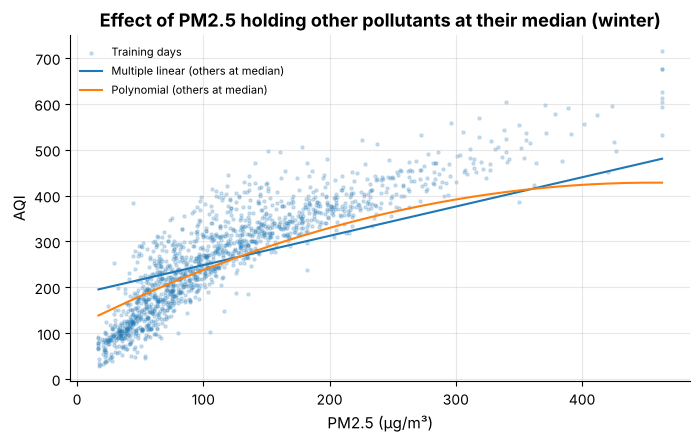

In [19]:
fig, ax = plt.subplots()
xs = np.linspace(X_tr["PM2.5"].min(), X_tr["PM2.5"].max(), 200)
base_row = X_tr[final_cols].median()
G = pd.DataFrame([base_row] * len(xs)); G["PM2.5"] = xs
for sname in ("Monsoon", "Post-monsoon", "Summer"):
    if sname in G: G[sname] = 0.0
ax.scatter(X_tr["PM2.5"], y_tr, s=5, alpha=.2, label="Training days")
ax.plot(xs, mf.predict(G[final_cols].assign(const=1.0)[["const"] + final_cols]), label="Multiple linear (others at median)")
ax.plot(xs, model_poly.predict(poly_design(G)), label="Polynomial (others at median)")
ax.set(title="Effect of PM2.5 holding other pollutants at their median (winter)", xlabel="PM2.5 (µg/m³)", ylabel="AQI")
ax.legend(fontsize=8)
save_figure(fig, "03_poly_curve"); plt.show()

## Part D: Model comparison, cross-validation and a time-based test

In [20]:
comp = pd.DataFrame(results)
comp = comp[["Model", "k", "R2", "Adj_R2", "RMSE", "MAE", "AIC"]]

def design(name, X, cols_):
    if name.startswith("Simple"):
        return X[["PM2.5"]].assign(const=1.0)[["const", "PM2.5"]]
    if name.startswith("Multiple"):
        return X[cols_].assign(const=1.0)[["const"] + cols_]
    Z = X[cols_].copy()   # centring only reparametrises the quadratic, so predictions do not depend on it
    Z["PM2.5"] = X["PM2.5"] - pm_mean; Z["PM2.5_sq"] = Z["PM2.5"] ** 2
    return Z.assign(const=1.0)[["const"] + list(Z.columns)]

kf = KFold(10, shuffle=True, random_state=SEED)
cv = {name: [] for name in comp["Model"]}
for tr_i, te_i in kf.split(X_all):
    Xa, Xb, ya, yb = X_all.iloc[tr_i], X_all.iloc[te_i], y_all.iloc[tr_i], y_all.iloc[te_i]
    for name in cv:
        m_ = sm.OLS(ya, design(name, Xa, final_cols)).fit()
        cv[name].append(np.sqrt(np.mean((yb - m_.predict(design(name, Xb, final_cols))) ** 2)))
comp["CV10 RMSE mean"] = [np.mean(cv[n]) for n in comp["Model"]]
comp["CV10 RMSE sd"] = [np.std(cv[n], ddof=1) for n in comp["Model"]]

is_tr = (df["Year"] <= 2018).values
time_rmse, time_r2 = [], []
for name in comp["Model"]:
    m_ = sm.OLS(y_all[is_tr], design(name, X_all[is_tr], final_cols)).fit()
    p_ = m_.predict(design(name, X_all[~is_tr], final_cols))
    met = regression_metrics(y_all[~is_tr], p_)
    time_rmse.append(met["RMSE"]); time_r2.append(met["R2"])
comp["2019 test RMSE"] = time_rmse
comp["2019 test R2"] = time_r2
save_table(comp.round(3), "regression_comparison")
comp.round(3)

,Model,k,R2,Adj_R2,RMSE,MAE,AIC,CV10 RMSE mean,CV10 RMSE sd,2019 test RMSE,2019 test R2
0,Simple linear (PM2.5),1,0.775,0.774,56.741,42.298,15888.151,55.901,4.222,47.099,0.839
1,Multiple linear (AIC-selected),9,0.881,0.878,41.260,31.385,15032.468,41.602,3.008,38.479,0.893
2,Polynomial (PM2.5 squared),10,0.885,0.882,40.475,30.731,14923.408,40.236,3.395,36.130,0.905


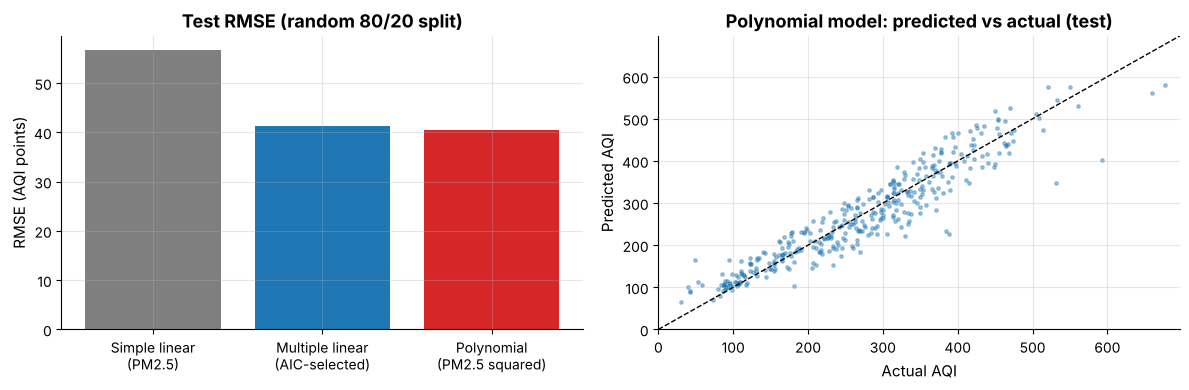

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(comp["Model"].str.replace(" (", "\n(", regex=False), comp["RMSE"], color=["C7", "C0", "C3"])
ax[0].set(title="Test RMSE (random 80/20 split)", ylabel="RMSE (AQI points)")
ax[1].scatter(y_te, pred_poly, s=6, alpha=.4)
lim = [0, max(y_te.max(), pred_poly.max()) + 20]
ax[1].plot(lim, lim, "k--", lw=1); ax[1].set(xlim=lim, ylim=lim, title="Polynomial model: predicted vs actual (test)",
                                          xlabel="Actual AQI", ylabel="Predicted AQI")
plt.tight_layout(); save_figure(fig, "03_model_comparison"); plt.show()

### Sensitivity check: does imputation change the answer?
Refit the final model on days with **no** imputed value at all.

In [22]:
obs_mask = (df.loc[X_tr.index, "Imputed"] == 0).values
m_obs = sm.OLS(y_tr[obs_mask], poly_design(X_tr[obs_mask])).fit()
sens = pd.DataFrame({"all training days": model_poly.params, "observed-only days": m_obs.params})
sens["% change"] = (sens["observed-only days"] / sens["all training days"] - 1) * 100
print(f"training days: {len(X_tr)} all, {obs_mask.sum()} with no imputed value")
sens.round(4)

training days: 1460 all, 1352 with no imputed value


,all training days,observed-only days,% change
const,173.5463,167.3304,-3.5817
PM2.5,1.0108,0.9213,-8.8571
PM10,0.3027,0.3562,17.6924
NOx,0.2016,0.1034,-48.6888
NH3,-0.3431,-0.2724,-20.6142
CO,6.0735,5.9190,-2.5446
O3,0.2925,0.2523,-13.7328
Summer,16.2791,13.4658,-17.2816
Monsoon,-3.1883,3.5082,-210.0325
Post-monsoon,13.7725,14.8138,7.5605


**Model comparison: conclusions**

| Model | Adj R² | Test RMSE | 10-fold CV RMSE | 2019 RMSE (trained 2015-18) |
| --- | --- | --- | --- | --- |
| Simple linear (PM2.5) | 0.774 | 56.7 | 55.9 ± 4.2 | 47.1 |
| Multiple linear (AIC-selected) | 0.878 | 41.3 | 41.6 ± 3.0 | 38.5 |
| Polynomial (PM2.5²) | 0.882 | 40.5 | 40.2 ± 3.4 | 36.1 |

* **Polynomial term:** the squared term is negative and highly significant (partial F = 114.5, p < 0.001; AIC falls
  from 15,032 to 14,923). The marginal effect of PM2.5 falls from 1.22 AQI per µg/m³ at 50 µg/m³ to 0.92 at 150
  and 0.47 at 300, matching how the AQI scale compresses its upper bands. The curve would peak near 456 µg/m³, at
  the edge of the data, so the model must not be extrapolated beyond the observed range (the app's sliders are
  limited to the 1st-99th percentile).
* Season remains jointly significant in the polynomial model (partial F = 18.6, p < 0.001). Individual season
  coefficients change between models because the curve absorbs part of the seasonal difference, so season effects
  are not interpreted causally.
* **Winner: the polynomial model**, on every measure: adjusted R², test RMSE and MAE, AIC, cross-validation and the
  forward-in-time 2019 test. Multiple regression gives the largest gain over the simple model (RMSE down 27%); the
  squared term adds a further 2-6%.
* **Generalisation over time:** training on 2015-2018 and testing on 2019 gives an *even lower* RMSE (36.1) and
  R² = 0.905, so the pollutant-to-AQI relationship is stable over time, as expected for a formula-based index.
* **Sensitivity to imputation:** dropping the 108 training days with any imputed value changes the PM2.5, CO and
  squared-term coefficients by less than 10%, so the main conclusions do not depend on imputation. NOx (-49%) and
  the small season coefficients are less stable and are interpreted cautiously.

## Export the final model for the app
The app reads plain numbers from `models/regression_model.json`, so the deployed app needs no statsmodels and cannot
break on a library version mismatch.

In [23]:
cols_ = list(model_poly.params.index)
ranges = {p: [float(df[p].quantile(.01)), float(df[p].quantile(.99)), float(df[p].median())] for p in POLLUTANTS}
season_medians = {s: {p: float(df.loc[df["Season"] == s, p].median()) for p in POLLUTANTS} for s in SEASONS}
reg_export = {
    "name": "Polynomial regression (PM2.5 centred, plus squared term)",
    "columns": cols_,
    "params": {k_: float(v) for k_, v in model_poly.params.items()},
    "cov": model_poly.cov_params().loc[cols_, cols_].values.tolist(),
    "scale": float(model_poly.scale),
    "df_resid": int(model_poly.df_resid),
    "final_cols": final_cols,
    "season_dummies": ["Monsoon", "Post-monsoon", "Summer"],
    "pm_mean": float(pm_mean),
    "test_metrics": {k_: float(v) for k_, v in results[-1].items() if k_ not in ("Model",)},
    "ranges": ranges,
    "season_medians": season_medians,
    "source": "cleaned dataset (notebook 01)",
    "n_train": int(len(X_tr)),
}
print("saved:", save_json(reg_export, "regression_model").name)

saved: regression_model.json


In [24]:
from src import predict_utils as pu
chk = X_te.head(200)
ours = np.array([pu.predict_aqi(chk.loc[i, POLLUTANTS].to_dict(), str(df.loc[i, "Season"]), reg_export)[0] for i in chk.index])
theirs = model_poly.predict(poly_design(chk)).values
print("max absolute difference (AQI points):", float(np.abs(ours - theirs).max()))
assert np.abs(ours - theirs).max() < 1e-6, "export does not match the fitted model"

max absolute difference (AQI points): 2.2737367544323206e-13
